# Fashion-MNIST Exploratory Data Analysis

This notebook performs the initial exploratory analysis of the Fashion-MNIST
dataset used in the P06 Clothing-Item Recognition project.

The dataset is loaded using the project's custom IDX loader from `src/data.py`.
The official Fashion-MNIST training and test split is preserved throughout the
project.

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))
from src.data import load_idx_images, load_idx_labels

In [3]:
DATA_DIR = PROJECT_ROOT / "data" / "raw"

TRAIN_IMAGES_PATH = DATA_DIR / "train-images-idx3-ubyte.gz"
TRAIN_LABELS_PATH = DATA_DIR / "train-labels-idx1-ubyte.gz"

TEST_IMAGES_PATH = DATA_DIR / "t10k-images-idx3-ubyte.gz"
TEST_LABELS_PATH = DATA_DIR / "t10k-labels-idx1-ubyte.gz"

In [4]:
X_train = load_idx_images(TRAIN_IMAGES_PATH)
y_train = load_idx_labels(TRAIN_LABELS_PATH)

X_test = load_idx_images(TEST_IMAGES_PATH)
y_test = load_idx_labels(TEST_LABELS_PATH)
print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", X_test.shape)
print("Test labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


In [5]:
CLASS_NAMES = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
]

In [6]:
print("Number of training samples:", len(X_train))
print("Number of test samples:", len(X_test))
print("Image dimensions:", X_train.shape[1:])
print("Number of classes:", len(np.unique(y_train)))
print("Pixel data type:", X_train.dtype)
print("Minimum pixel intensity:", X_train.min())
print("Maximum pixel intensity:", X_train.max())

Number of training samples: 60000
Number of test samples: 10000
Image dimensions: (28, 28)
Number of classes: 10
Pixel data type: uint8
Minimum pixel intensity: 0
Maximum pixel intensity: 255


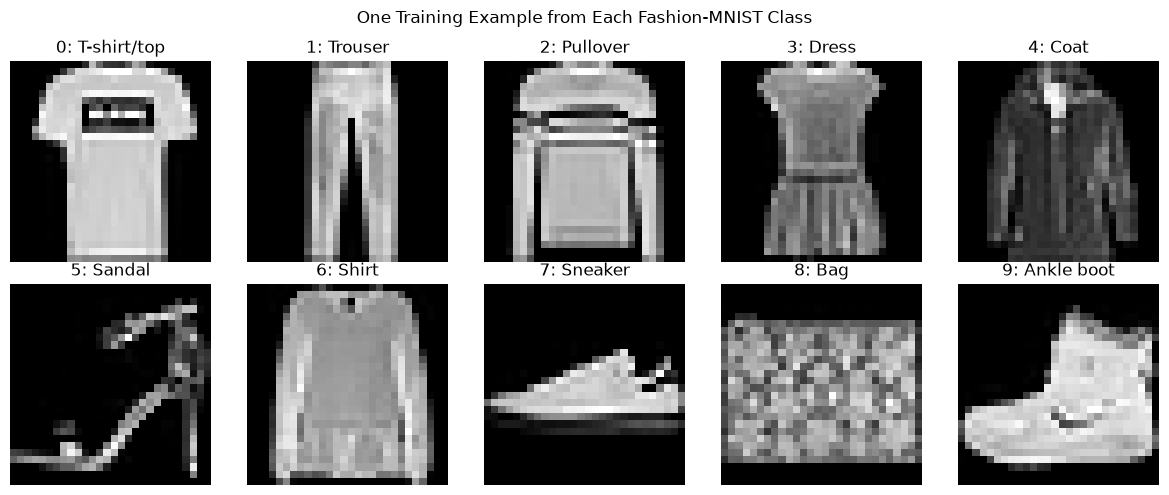

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for class_id, ax in enumerate(axes.flat):
    sample_index = np.where(y_train == class_id)[0][0]

    ax.imshow(X_train[sample_index], cmap="gray")
    ax.set_title(f"{class_id}: {CLASS_NAMES[class_id]}")
    ax.axis("off")

plt.suptitle("One Training Example from Each Fashion-MNIST Class")
plt.tight_layout()
plt.show()

### Sample Image Observations

The dataset contains low-resolution grayscale images with a fixed size of
28×28 pixels.

Some categories have visually distinctive silhouettes, such as trousers, bags,
and footwear. In contrast, upper-body clothing categories such as T-shirt/top,
pullover, coat, and shirt appear more visually similar at this resolution.

This suggests that the upper-body clothing classes may be more difficult to
separate than classes with more distinctive overall shapes. This hypothesis
will be revisited after model evaluation using the confusion matrix.

In [8]:
class_ids, class_counts = np.unique(y_train, return_counts=True)

for class_id, count in zip(class_ids, class_counts):
    print(
        f"{class_id}: {CLASS_NAMES[class_id]} -> {count} training samples"
    )

0: T-shirt/top -> 6000 training samples
1: Trouser -> 6000 training samples
2: Pullover -> 6000 training samples
3: Dress -> 6000 training samples
4: Coat -> 6000 training samples
5: Sandal -> 6000 training samples
6: Shirt -> 6000 training samples
7: Sneaker -> 6000 training samples
8: Bag -> 6000 training samples
9: Ankle boot -> 6000 training samples


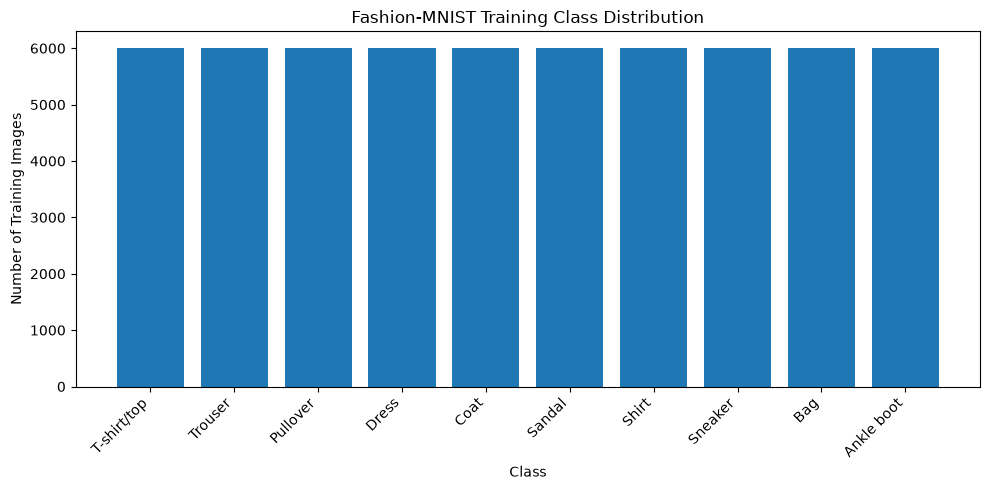

In [9]:
plt.figure(figsize=(10, 5))

plt.bar(CLASS_NAMES, class_counts)

plt.title("Fashion-MNIST Training Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Training Images")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

### Class Distribution

The official Fashion-MNIST training set is balanced, containing 6,000 examples
for each of the ten classes.

Therefore, overall accuracy is meaningful as a primary classification metric
for this dataset. However, macro F1-score and per-class precision and recall
will also be reported because the project aims to understand which individual
clothing categories are easier or harder to classify.